Student Name : Alex Carter , Student number : 240355490

In [3]:
#importing packages that I will need for this assigment
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (classification_report, confusion_matrix, mean_absolute_error, mean_squared_error, r2_score)
from sklearn.utils.class_weight import compute_class_weight
import torch
import torch.nn as nn
import torch.optim as optim

In [4]:
########## Section A: ##########

In [5]:
election_data = pd.read_csv("Election_results.csv")

In [6]:
# Using .head to get an initial view of the Data
print(election_data.head())

  constituency_id  constituency_name country/region electorate  con_votes  \
0             NaN   Belfast Victoria        Ireland      19494        NaN   
1             NaN             Carlow        Ireland        NaN        NaN   
2             NaN         Cavan East        Ireland        NaN        NaN   
3             NaN         Clare West        Ireland        NaN        NaN   
4             NaN          Cork City        Ireland      45017     2519.0   

   con_share lib_votes  lib_share lab_votes  lab_share  natSW_votes  \
0        NaN       NaN        NaN       NaN        NaN          NaN   
1        NaN       NaN        NaN       NaN        NaN          NaN   
2        NaN       NaN        NaN       NaN        NaN          NaN   
3        NaN       NaN        NaN       NaN        NaN          NaN   
4      0.082       NaN        NaN       NaN        NaN          NaN   

   natSW_share  oth_votes  oth_share total_votes  turnout election  \
0          NaN    13317.0      1.000    

In [7]:
# Remove the 'boundary_set' column
election_data = election_data.drop(columns=['boundary_set'])

In [8]:
# Fill missing values with zeros
election_data = election_data.fillna(0)

In [9]:
# Remove rows where 'total_votes' is '-1'
election_data = election_data[election_data['total_votes'] != '-1']

In [10]:
# Remove rows where 'electorate', 'lib_votes', or 'lab_votes' are spaces
election_data = election_data[
    (election_data['electorate'] != ' ') & 
    (election_data['lib_votes'] != ' ') & 
    (election_data['lab_votes'] != ' ')]

In [11]:
# Convert specified columns to integer type
int_columns = ['electorate', 'lib_votes', 'lab_votes', 'con_votes', 'natSW_votes', 'oth_votes']
election_data[int_columns] = election_data[int_columns].astype(int)

In [12]:
# Create 'Result' column based on the highest vote share
vote_shares = ['con_share', 'lab_share', 'lib_share', 'natSW_share', 'oth_share']
election_data['Result'] = election_data[vote_shares].idxmax(axis=1).map({
    'con_share': 'con', 'lab_share': 'lab', 'lib_share': 'lib', 
    'natSW_share': 'nat', 'oth_share': 'oth'})

In [13]:
# Remove rows where 'Result' is not one of the specified parties
valid_results = ['con', 'lab', 'lib', 'nat', 'oth']
election_data = election_data[election_data['Result'].isin(valid_results)]

In [14]:
# Count the number of rows and columns
num_rows, num_columns = election_data.shape
print(f"\nAfter initial data cleaning and processing:")
print(f"Number of rows: {num_rows}")
print(f"Number of columns: {num_columns}")


After initial data cleaning and processing:
Number of rows: 18033
Number of columns: 18


In [15]:
# Display the first few rows of the cleaned dataset
# This shows our inital changes have taken effect
print(election_data.head())

   constituency_id                          constituency_name country/region  \
0                0                           Belfast Victoria        Ireland   
4                0                                  Cork City        Ireland   
8              548                             Aberdeen North       Scotland   
9              549                             Aberdeen South       Scotland   
10             580  Aberdeenshire And Kincardineshire Central       Scotland   

    electorate  con_votes  con_share  lib_votes  lib_share  lab_votes  \
0        19494          0      0.000          0      0.000          0   
4        45017       2519      0.082          0      0.000          0   
8        33072          0      0.000          0      0.000          0   
9        38800      10625      0.624       3535      0.208          0   
10       26315       6546      0.526       5908      0.474          0   

    lab_share  natSW_votes  natSW_share  oth_votes  oth_share total_votes  \
0  

In [16]:
########## Section B: ##########

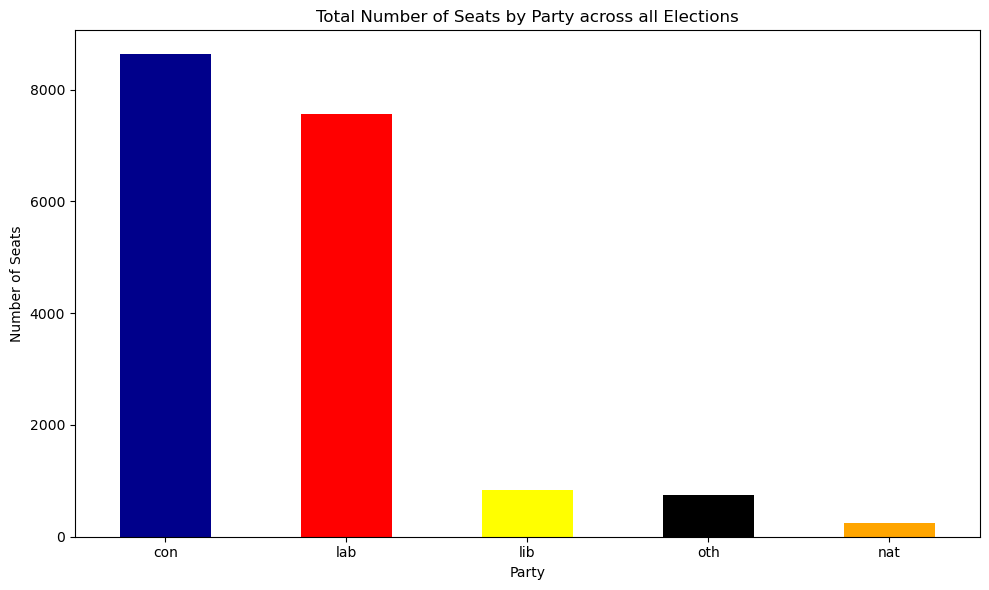

Result
con    8629
lab    7563
lib     844
oth     755
nat     242
Name: count, dtype: int64


In [17]:
#Create a bar chart showing the total number of seats for the 5 parties
seat_counts = election_data['Result'].value_counts()

plt.figure(figsize=(10, 6))
seat_counts.plot(kind='bar', color=['darkblue', 'red', 'yellow', 'black', 'orange'])
plt.title('Total Number of Seats by Party across all Elections')
plt.xlabel('Party')
plt.ylabel('Number of Seats')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(seat_counts)

Section B Comments:

Firstly, I personally am incredibly enthuastic about British politics, so it's really fascinating to see the comparative cumulative result of every seat since 1918 to 2019. The British Conservative party is often described as "The greatest election winning force in European history", and this graph goes to show how they earnt that reputation. What I also find interesting is how relatively close behind Labour are. This graph represents 28 General elections that labour were on the ballot, out of which they won an overall of 11 General elections. What I am trying to say, is that Labour have won a relatively comparable amount of seats to the conservatives, but won far fewer elections overall. (Conservative victories = 17) It is also worth commenting that this graph is a direct refelction of the First Past The Post (FPTP) electoral system used in the UK. This is reflected in the relatively low amount of seats won by parties other than con or lab, I suspect if we compared this graph to the same graph of a country which uses proportional representation, we would see that the other country has a much more evenly distributed amount of seats.

In [19]:
########## Section C: ##########

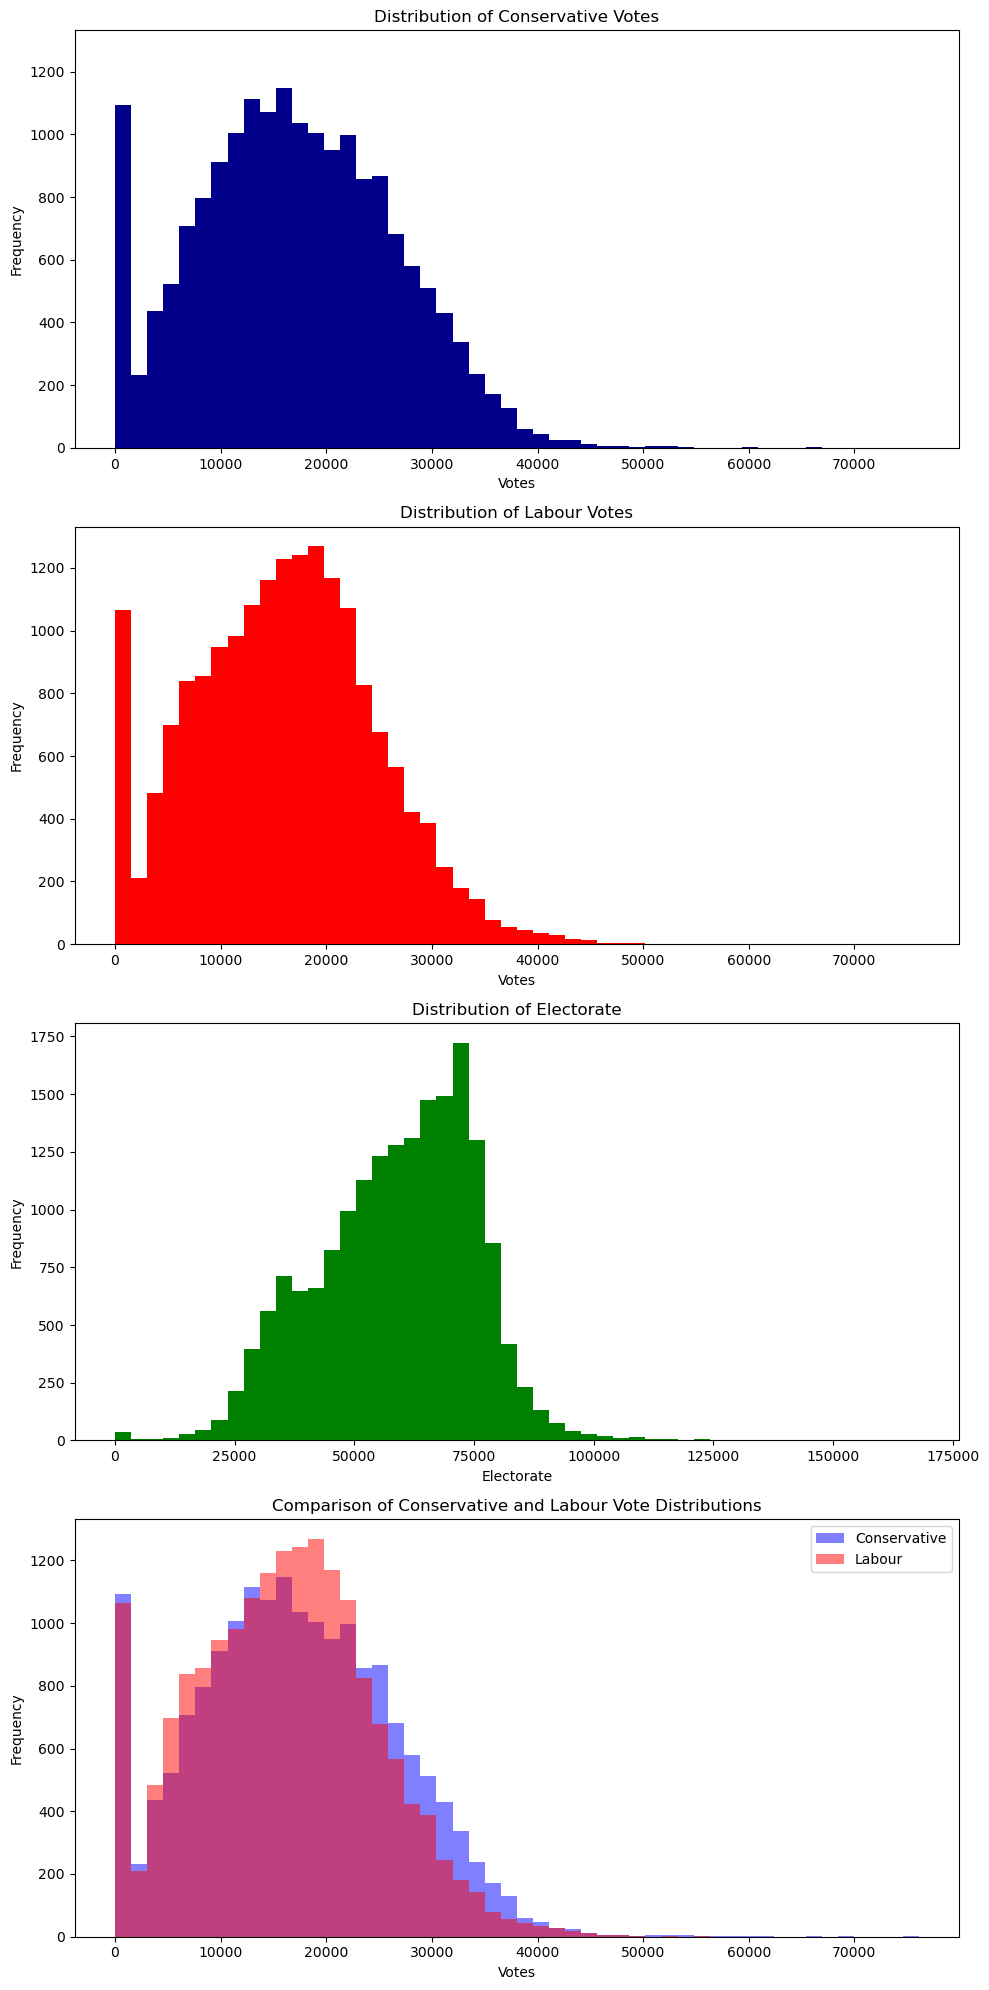

In [20]:
# outlining the structure of my final figure
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(10, 20))

# Determine the range for con_votes and lab_votes (to ensure they are on the same scale for later on)
vote_max = max(election_data['con_votes'].max(), election_data['lab_votes'].max())
vote_min = min(election_data['con_votes'].min(), election_data['lab_votes'].min())

# Histogram for con_votes - changed to dark blue
ax1.hist(election_data['con_votes'], bins=50, range=(vote_min, vote_max), color='darkblue')
ax1.set_title('Distribution of Conservative Votes')
ax1.set_xlabel('Votes')
ax1.set_ylabel('Frequency')

# Histogram for lab_votes - changed to red
ax2.hist(election_data['lab_votes'], bins=50, range=(vote_min, vote_max), color='red')
ax2.set_title('Distribution of Labour Votes')
ax2.set_xlabel('Votes')
ax2.set_ylabel('Frequency')

# Ensure the y-axis is the same for both vote histograms
y_max = max(ax1.get_ylim()[1], ax2.get_ylim()[1])
ax1.set_ylim(0, y_max)
ax2.set_ylim(0, y_max)

# Histogram for electorate - changed to green
ax3.hist(election_data['electorate'], bins=50, color='green')
ax3.set_title('Distribution of Electorate')
ax3.set_xlabel('Electorate')
ax3.set_ylabel('Frequency')

# Overlapping histograms 
ax4.hist(election_data['con_votes'], bins=50, alpha=0.5, label='Conservative', color='blue', range=(vote_min, vote_max))
ax4.hist(election_data['lab_votes'], bins=50, alpha=0.5, label='Labour', color='red', range=(vote_min, vote_max))
ax4.set_title('Comparison of Conservative and Labour Vote Distributions')
ax4.set_xlabel('Votes')
ax4.set_ylabel('Frequency')
ax4.legend()

plt.tight_layout()
plt.show()

Section C comments:

The first three histograms seem to indicate that the votes for labour and Conservative follow a Gaussian distribution. The distribution of the total electorate also seems to follow a Gaussian distribution. In the fourth additional figure, I have layered the con/lab votes over each other so we can compare distributions more effectively. In this fourth figure we can see that the Conservative distribution leans more to the right, which is what we would expect as the party Which has won more elections, should more frequently win larger portions of votes.

In [22]:
########## Section D: ###########

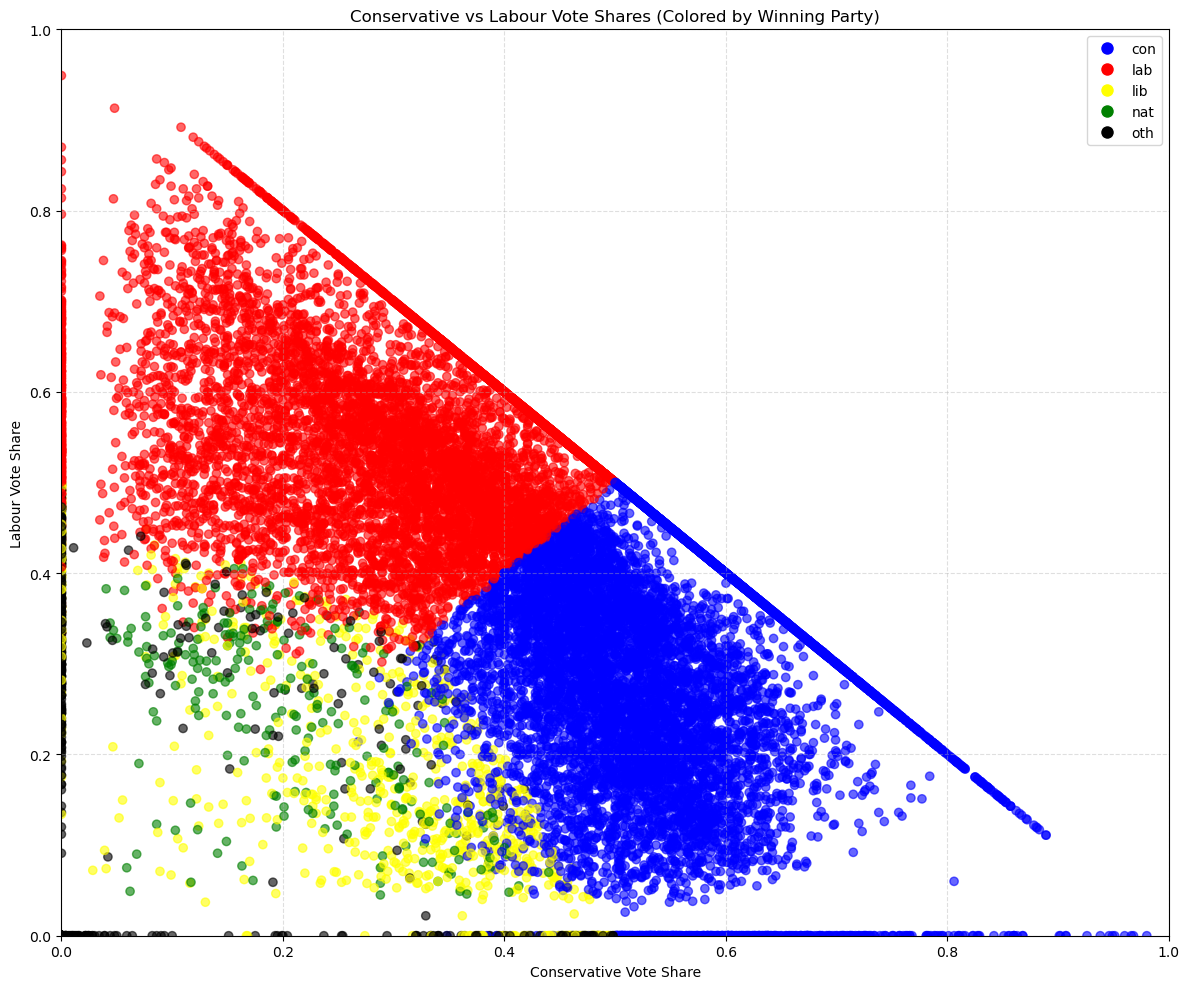

In [23]:
plt.figure(figsize=(12, 10))

# Define color map for results
color_map = {'con': 'blue', 'lab': 'red', 'lib': 'yellow', 'nat': 'green', 'oth': 'black'}

# Create scatterplot
scatter = plt.scatter(election_data['con_share'], 
                      election_data['lab_share'],
                      c=election_data['Result'].map(color_map),
                      alpha=0.6)
#Axis Labels

plt.xlabel('Conservative Vote Share')
plt.ylabel('Labour Vote Share')
plt.title('Conservative vs Labour Vote Shares (Colored by Winning Party)')

#legend info
legend_elements = [plt.Line2D([0], [0], marker='o', color='w', label=party, 
                   markerfacecolor=color, markersize=10) 
                   for party, color in color_map.items()]
plt.legend(handles=legend_elements)

plt.grid(True, linestyle='--', alpha=0.4)
plt.xlim(0, 1)
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

Section D comments:

There are a few comments we can make on some dividing lines that appear in the scatterplot. Firstly, we can see that in most instances, as conservative vote share decreases, labour vote share increases (and visa versa)this makes sense when you consider that these two are the two major parties which most strongly oppose each other. (diagonol dividing line) Then we can see that as vote share for conservatives and labour decrease, we are more likely to see parties win which would be considered minor parties like the SNP, lib dem, or independents listed as "oth" for this assignment. This also makes sense. We can also see vertical and horizontal dividing lines, this makes sense as where con/lab have over 50% of the vote, they are always going to be the winner in that constituency.

In [25]:
########## Section E ##########

In [26]:
# Removing the specified columns
columns_to_remove = ['country/region', 'constituency_id', 'turnout', 'con_votes',
                     'lib_votes', 'lab_votes', 'oth_votes', 'natSW_votes', 'total_votes', 'electorate']
election_data = election_data.drop(columns=columns_to_remove)

In [27]:
# Creating election_list
election_list = election_data['election'].unique().tolist()

In [28]:
# Creating average columns for each party
for party in ['con', 'lab', 'lib', 'natSW', 'oth']:
    election_data[f'{party}_av'] = election_data.groupby('election')[f'{party}_share'].transform('mean')

In [29]:
# Creating constituency_list
constituency_list = election_data['constituency_name'].unique().tolist()

In [30]:
# Creating bias columns for each party
for party in ['con', 'lab', 'lib', 'natSW', 'oth']:
    election_data[f'{party}_bias'] = election_data.groupby('constituency_name')[f'{party}_share'].transform('mean')

In [31]:
# Creating diff columns for each party
for party in ['con', 'lab', 'lib', 'natSW', 'oth']:
    election_data[f'{party}_diff'] = election_data[f'{party}_bias'] - election_data[f'{party}_av']

In [32]:
# Calculating pairwise correlation matrix, excluding non-numeric columns
numeric_columns = election_data.select_dtypes(include=['float64', 'int64']).columns
correlation_matrix = election_data[numeric_columns].corr()

In [33]:
# Finding correlations above 0.89 or below -0.52
high_correlations = correlation_matrix[(correlation_matrix > 0.89) | (correlation_matrix < -0.52)]
high_correlations = high_correlations.stack().reset_index()
high_correlations.columns = ['Variable 1', 'Variable 2', 'Correlation']
high_correlations = high_correlations[high_correlations['Variable 1'] != high_correlations['Variable 2']]
high_correlations = high_correlations.drop_duplicates(subset=['Variable 1', 'Variable 2'])

In [34]:
#Displaying the requested output
print("Correlations above 0.89 or below -0.52:")
print(high_correlations)

Correlations above 0.89 or below -0.52:
    Variable 1  Variable 2  Correlation
7       lab_av      oth_av    -0.525163
9       lib_av    lib_diff    -0.537051
11      oth_av      lab_av    -0.525163
14    con_bias    con_diff     0.898198
16    lab_bias    lib_bias    -0.526211
17    lab_bias    lab_diff     0.901511
18    lib_bias    lab_bias    -0.526211
21  natSW_bias  natSW_diff     0.962614
23    con_diff    con_bias     0.898198
25    lab_diff    lab_bias     0.901511
27    lib_diff      lib_av    -0.537051
29  natSW_diff  natSW_bias     0.962614


In [35]:
#There are some clear correlations here, for example lab bias and lab diff indicates that seats that have historically voted labour
#seem as though they may be more likely to vote labour than the national average.

In [36]:
# Print the shape of the dataframe after transformations
print(f"\nShape of the dataframe after transformations: {election_data.shape}")

# Display the first few rows of the transformed dataset
print("\nFirst few rows of the transformed dataset:")
print(election_data.head())


Shape of the dataframe after transformations: (18033, 23)

First few rows of the transformed dataset:
                            constituency_name  con_share  lib_share  \
0                            Belfast Victoria      0.000      0.000   
4                                   Cork City      0.082      0.000   
8                              Aberdeen North      0.000      0.000   
9                              Aberdeen South      0.624      0.208   
10  Aberdeenshire And Kincardineshire Central      0.526      0.474   

    lab_share  natSW_share  oth_share election Result    con_av    lab_av  \
0         0.0          0.0      1.000     1918    oth  0.384089  0.192208   
4         0.0          0.0      0.918     1918    oth  0.384089  0.192208   
8         0.0          0.0      1.000     1918    oth  0.384089  0.192208   
9         0.0          0.0      0.168     1918    con  0.384089  0.192208   
10        0.0          0.0      0.000     1918    con  0.384089  0.192208   

    ...

In [37]:
#outputting the above to show that the specified changes have taken place.

In [38]:
########## Section F: ##########

In [39]:
# Ensure 'election' column is numeric, as you can see it is being read as an object above which was causing errors for the rest of this section
# This needed to be done because later I split the data for training/test by using a command which requires the column to be an int
# to differenciate between different election years.
election_data['election'] = pd.to_numeric(election_data['election'], errors='coerce')

In [40]:
# Split the data into training (before 2024) and test (2024) sets
election_data_2024 = election_data[election_data['election'] == 2024].copy()
election_data_train = election_data[election_data['election'] < 2024].copy()

In [41]:
# Prepare the features (X) and target variable (y) for training data
X_train = election_data_train[['con_av', 'lab_av', 'lib_av', 'natSW_av', 'oth_av', 
                               'con_bias', 'lab_bias', 'lib_bias', 'natSW_bias', 'oth_bias', 
                               'con_diff', 'lab_diff', 'lib_diff', 'natSW_diff', 'oth_diff']]
y_train = election_data_train['Result']

In [42]:
# Prepare the features (X) for test data (2024 election)
X_test = election_data_2024[['con_av', 'lab_av', 'lib_av', 'natSW_av', 'oth_av', 
                             'con_bias', 'lab_bias', 'lib_bias', 'natSW_bias', 'oth_bias', 
                             'con_diff', 'lab_diff', 'lib_diff', 'natSW_diff', 'oth_diff']]
y_test = election_data_2024['Result']

In [43]:
# Create and train the logistic regression model
model = LogisticRegression(multi_class='ovr', max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, multi_class='ovr')

In [44]:
# Make predictions on the test set (2024 election)
y_pred = model.predict(X_test)

In [45]:
# Calculate the accuracy of the model
accuracy = model.score(X_test, y_test)
print(f"Model Accuracy: {accuracy:.4f}")

# Generate and print the classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Generate and print the confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Count the actual and predicted seats for each party
actual_seats = y_test.value_counts()
predicted_seats = pd.Series(y_pred).value_counts()

print("\nActual Seats:")
print(actual_seats)
print("\nPredicted Seats:")
print(predicted_seats)

Model Accuracy: 0.7462

Classification Report:
              precision    recall  f1-score   support

         con       0.46      0.57      0.51       115
         lab       0.85      0.89      0.87       379
         lib       0.95      0.51      0.67        72
         nat       0.61      0.85      0.71        13
         oth       0.64      0.45      0.53        71

    accuracy                           0.75       650
   macro avg       0.70      0.66      0.66       650
weighted avg       0.76      0.75      0.74       650


Confusion Matrix:
[[ 66  25   2   4  18]
 [ 38 339   0   2   0]
 [ 34   0  37   1   0]
 [  1   1   0  11   0]
 [  5  34   0   0  32]]

Actual Seats:
Result
lab    379
con    115
lib     72
oth     71
nat     13
Name: count, dtype: int64

Predicted Seats:
lab    399
con    144
oth     50
lib     39
nat     18
Name: count, dtype: int64


In [46]:
#unsure why actual seats is outputting 379 when official number is 411, did I make a mistake somewhere?

In [47]:
# Let's look at constituencies where Labour came second to 'oth'
oth_wins = election_data[
    (election_data['election'] == 2024) & 
    (election_data['Result'] == 'oth')
]

print("Number of 'oth' wins:", len(oth_wins))
print("\nTop 10 'oth' winning constituencies by Labour share:")
print(oth_wins.sort_values('lab_share', ascending=False)[
    ['constituency_name', 'lab_share', 'oth_share']
].head(10))

Number of 'oth' wins: 71

Top 10 'oth' winning constituencies by Labour share:
              constituency_name  lab_share  oth_share
18180                 Rotherham   0.451397   0.472138
18258         Stratford and Bow   0.440774   0.443191
17749       Birmingham Ladywood   0.425326   0.467263
18223             South Shields   0.410656   0.439170
17765  Bolton South and Walkden   0.408692   0.440915
17998              Ilford South   0.401676   0.416590
17864               Derby South   0.387791   0.425065
17772             Bradford East   0.378816   0.477160
18049               Luton North   0.378810   0.387431
17994              Huddersfield   0.375974   0.417378


In [48]:
#this actually explains why, because 'oth' includes independents and minor parties like green and reform, sometimes it appears
#that 'oth' has won  because it contains the highest vote share, but this isn't necessarily the case. Birmingham Ladywood for example was a labour
#hold with a very popular independent candidate that came close to winning. 

To comment on the accuracy of these results: 

we can see the overall accuracy of this model is just under 0.75 which means it can successfully classify results 3 quaters of the time. This is good from quite a simple model, but is limited compared the model which we will build later on. This is because this model, is just using x to predict y based on the training data, but we can improve on this method in PyTorch. 

In [50]:
########## Section G: ##########

In [51]:
# Split the data into training (before 2024) and test (2024) sets
X_columns = ['con_av', 'lab_av', 'lib_av', 'natSW_av', 'oth_av',  
             'con_bias', 'lab_bias', 'lib_bias', 'natSW_bias', 'oth_bias',  
             'con_diff', 'lab_diff', 'lib_diff', 'natSW_diff', 'oth_diff']  


In [52]:
# Prepare training data (pre-2024)
X_train = election_data[election_data['election'] < 2024][X_columns]
y_train = election_data[election_data['election'] < 2024]['lab_share']

In [53]:
# Prepare test data (2024)
X_test = election_data[election_data['election'] == 2024][X_columns]
y_test = election_data[election_data['election'] == 2024]['lab_share']

In [54]:
# Create and train the linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [55]:
# Make predictions on test set
y_pred = model.predict(X_test)

In [56]:
# Calculate error metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

Section g Comments:

R squared score for this model indicates a strong correlation between our model and actual labour vote share. MSE is very low as well, which indicates relatively low variation of data points from the mean which has been plotted. This suggests our model is good at predicting labour vote share based on previous election data, but is limited in some ways too. In the broadest sense, a major limitation is that this model cannot take external factors into account, and can only deal with training/test data.

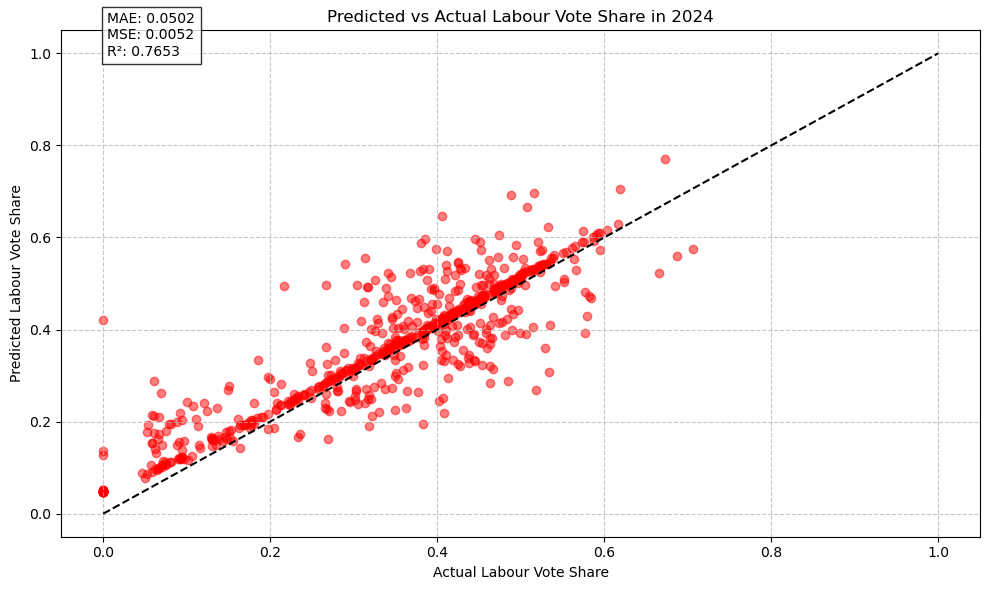

In [58]:
# Create scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color='red')  # Changed to red
plt.plot([0, 1], [0, 1], 'k--')  # Changed to black dotted ('k--')
plt.xlabel('Actual Labour Vote Share')
plt.ylabel('Predicted Labour Vote Share')
plt.title('Predicted vs Actual Labour Vote Share in 2024')

# Add text box with metrics
metrics_text = f'MAE: {mae:.4f}\nMSE: {mse:.4f}\nR²: {r2:.4f}'
plt.text(0.05, 0.95, metrics_text, transform=plt.gca().transAxes, 
         bbox=dict(facecolor='white', alpha=0.8))

plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [59]:
########## Section H: ###########

In [60]:
# 1. Filter rows for main parties
election_data = election_data[election_data['Result'].isin(['con', 'lab', 'lib'])]

# 2. Remove specified columns
columns_to_remove = ['con_share', 'lib_share', 'lab_share', 'natSW_share',
                    'oth_share', 'constituency_name', 'natSW_av', 'oth_av',  # Changed 'nat_av' to 'natSW_av'
                    'natSW_bias', 'oth_bias', 'natSW_diff', 'oth_diff']     # Changed 'nat_bias' and 'nat_diff' to 'natSW_bias' and 'natSW_diff'
election_data = election_data.drop(columns=columns_to_remove)

# 3. Make a copy
election_data_copy = election_data.copy()

# 4. Create Result_number column
result_mapping = {'con': 0, 'lab': 1, 'lib': 2}
election_data_copy['Result_number'] = election_data_copy['Result'].map(result_mapping)

# 5. Remove Result column
election_data_copy = election_data_copy.drop(columns=['Result'])

# 6. Normalize the specified columns
columns_to_normalize = ['con_av', 'lab_av', 'lib_av', 
                       'con_bias', 'lab_bias', 'lib_bias',
                       'con_diff', 'lab_diff', 'lib_diff']

for column in columns_to_normalize:
    min_val = election_data_copy[column].min()
    max_val = election_data_copy[column].max()
    election_data_copy[column] = (election_data_copy[column] - min_val) / (max_val - min_val)

# 7. Split into train and test
X_train = election_data_copy[election_data_copy['election'] < 2024][columns_to_normalize]
y_train = election_data_copy[election_data_copy['election'] < 2024]['Result_number']
X_test = election_data_copy[election_data_copy['election'] == 2024][columns_to_normalize]
y_test = election_data_copy[election_data_copy['election'] == 2024]['Result_number']

In [61]:
# Calculate class weights 
class_weights = compute_class_weight('balanced', 
                                   classes=np.unique(y_train.values),
                                   y=y_train.values)
class_weights = torch.FloatTensor(class_weights)

# Convert data to PyTorch tensors 
X_train_tensor = torch.FloatTensor(X_train.values)
y_train_tensor = torch.LongTensor(y_train.values)
X_test_tensor = torch.FloatTensor(X_test.values)
y_test_tensor = torch.LongTensor(y_test.values)

# MLP model definition
class SimpleMLPModel(nn.Module):
    def __init__(self, input_size=9, hidden_size=64, num_classes=3):
        super(SimpleMLPModel, self).__init__()
        self.layer1 = nn.Linear(input_size, hidden_size)
        self.layer2 = nn.Linear(hidden_size, hidden_size)
        self.layer3 = nn.Linear(hidden_size, num_classes)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.2)
    
    def forward(self, x):
        x = self.relu(self.layer1(x))
        x = self.dropout(x)
        x = self.relu(self.layer2(x))
        x = self.dropout(x)
        x = self.layer3(x)
        return x

# Initialize model with standard CrossEntropyLoss
model = SimpleMLPModel()
criterion = nn.CrossEntropyLoss()  # No weights parameter
optimizer = optim.Adam(model.parameters(), lr=0.005)

# Training loop
num_epochs = 1000
print_interval = 100

for epoch in range(num_epochs):
    model.train()
    # Forward pass
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    
    # Backward pass and optimization
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if (epoch + 1) % print_interval == 0:
        model.eval()
        with torch.no_grad():
            test_outputs = model(X_test_tensor)
            _, predicted = torch.max(test_outputs.data, 1)
            accuracy = (predicted == y_test_tensor).sum().item() / y_test_tensor.size(0)
            print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}, Accuracy: {accuracy:.4f}')

# Test the model
model.eval()
with torch.no_grad():
    # Make predictions
    test_outputs = model(X_test_tensor)
    _, predicted = torch.max(test_outputs.data, 1)
    
    # Calculate accuracy
    accuracy = (predicted == y_test_tensor).sum().item() / y_test_tensor.size(0)
    print(f'\nTest Accuracy: {accuracy:.4f}')
    
    # Generate predictions and reports
    y_pred = predicted.numpy()
    y_true = y_test_tensor.numpy()
    
    print('\nClassification Report:')
    print(classification_report(y_true, y_pred, 
                              target_names=['Conservative', 'Labour', 'Liberal']))
    
    print('\nConfusion Matrix:')
    print(confusion_matrix(y_true, y_pred))
    
    # Count seats
    parties = ['Conservative', 'Labour', 'Liberal']
    for party_idx, party_name in enumerate(parties):
        actual_count = (y_true == party_idx).sum()
        predicted_count = (y_pred == party_idx).sum()
        print(f'\n{party_name}:')
        print(f'Actual seats: {actual_count}')
        print(f'Predicted seats: {predicted_count}')

Epoch [100/1000], Loss: 0.3242, Accuracy: 0.8039
Epoch [200/1000], Loss: 0.3118, Accuracy: 0.8127
Epoch [300/1000], Loss: 0.3075, Accuracy: 0.7951
Epoch [400/1000], Loss: 0.3039, Accuracy: 0.8057
Epoch [500/1000], Loss: 0.3018, Accuracy: 0.8021
Epoch [600/1000], Loss: 0.3012, Accuracy: 0.8004
Epoch [700/1000], Loss: 0.2987, Accuracy: 0.8057
Epoch [800/1000], Loss: 0.2965, Accuracy: 0.8021
Epoch [900/1000], Loss: 0.2944, Accuracy: 0.8021
Epoch [1000/1000], Loss: 0.2914, Accuracy: 0.8004

Test Accuracy: 0.8004

Classification Report:
              precision    recall  f1-score   support

Conservative       0.51      0.63      0.56       115
      Labour       0.89      0.90      0.90       379
     Liberal       0.97      0.53      0.68        72

    accuracy                           0.80       566
   macro avg       0.79      0.69      0.72       566
weighted avg       0.82      0.80      0.80       566


Confusion Matrix:
[[ 73  41   1]
 [ 37 342   0]
 [ 34   0  38]]

Conservative:
A

Discussion of accuracy : 

The accuracy of this model on test data is consistently much better (at least 5%) than the logistical regression model used earlier in this coursework. This makes sense as comparitively, this is a much more sophisticated model. The accuracy of this model on test data is consistently between 80-85% and seems to make errors mostly between conservative and libdem seats, which makes sense in the real life context of the problem. I would have liked to improve the accuracy, and could have by spending much more time testing different learning rates, hidden layers and optimisation models, but ultimately had to settle on this to give myself time to work on different parts of the coursework. 